In [30]:
%load_ext autoreload
%autoreload 2

import iml  # helper functions and classes (see iml/)
import numpy as np  # array processing
import pandas as pd  # dataframes, reading files
import matplotlib.pyplot as plt  # making plots

from matplotlib.colors import Normalize
from matplotlib.collections import LineCollection
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


**Group members:**
- BALACHANDRAN Vanathy
- DOS SANTOS RAMOS Sarah Melyssa
- OZAN Saadet

## Part 1: Partial Derivatives

### (a) 
#### 1. Compute the derivative $\partial L / \partial x(i).$
>$\partial / \partial x(i) \sum_{j=1}^N |\mu - x(j)| $

>= $\partial / \partial x(i) |\mu - x(i)|$

>= $\operatorname{sign}(x(i)-\mu)$

> Therefore,  

>$$ \partial L / \partial x(i) =\begin{cases} 1 & \text{if } x(i) > \mu \\ -1 & \text{if } x(i) < \mu \end{cases}$$

#### 2. Leaving all other variables fixed, what value of $x(i)$ minimizes $L$?

> So $L$ decreases until $x(i)$ reaches $\mu$ and increases afterwards. Hence $L$ is minimized at

> $$x(i) = \mu = \theta^3$$

### (b)
#### 1. Compute the derivative $\partial L / \partial \mu.$ 

> $\frac {\partial} {\partial\mu} \sum_{i=1}^N |\mu - x(i)|$

> = $\sum_{i=1}^N \frac {\partial} {\partial\mu}$ $|\mu - x(i)|$

> = $\sum_{i=1}^N$ $\operatorname{sign}(\mu-x(i))$ 

> $= \begin{cases} 1 & \text{if } \mu > x(i) \\ -1 & \text{if } \mu < x(i)  \end{cases}$

<br>

> Also, $\frac {\partial} {\partial\mu \lambda\mu^2}$ = $2\lambda\mu$

<br>

> Therefore : 

> $$\frac {\partial L} {\partial \mu} = \sum_{i=1}^N |\mu - x(i)| + 2\lambda\mu$$

#### 2. If $\lambda = 0,$ what values of $\mu$ minimize $L$?
> If $\lambda = 0$ : 

> $L$ = $\sum_{i=1}^N$ $|\mu - x(i)|$

> Every data point $x(i)$ below $\mu$ contributes +1 to the derivate, whereas every $x(i)$ above $\mu$ contributes -1.
> Thus, the minimum occurs when the data points are balanced on either sides of $\mu$ :  

> L is minimized when $\mu$ is the median of the data points $x(i)$.

### (c) Compute the derivative $\partial L / \partial \theta.$

> Since $\mu = \theta^3$ :

> $\frac {\partial L} {\partial \theta} = \frac {\partial L} {\partial \mu} \frac {d\mu} {d\theta}  $

<br>

> Based on quesion b, we know that : 

> $\frac {\partial L} {\partial \mu}= \sum_{i=1}^N |\mu - x(i)| + 2\lambda\mu$

<br>

> And : 

> $\frac {d\mu} {d\theta} = 3\theta^2$

<br>

> Hence, $\frac {\partial L} {\partial \theta}$ =

> $$3\theta^2[\sum_{i=1}^N |\theta^3 - x(i)| + 2\lambda\theta^3]$$

### (d) Compute $ \frac{\partial}{\partial z_i} \ln \operatorname{softmax}(z)_j.$
> (Hint: first define $Z = \ln \sum_{j = 1}^k e^{z_j}$ and compute $\partial Z / \partial z_j.$)

> $\frac {\partial Z}{\partial z_j}$ = $ \frac {\frac{\partial}{\partial z_j} \sum_{l = 1}^k e^{z_l} } {\sum_{l = 1}^k e^{z_l}}  $ 

> = $\frac {e^{z_j}}{\sum_{l = 1}^k e^{z_l}}$

> = $\operatorname{softmax}(z)_j$

<br>

> Hence, 

> $\operatorname{softmax}(z)_j = \frac{e^{z_j}}{\sum_{l = 1}^k e^{z_l}}$

> $\ln\operatorname{softmax}(z)_j = z_j - Z$

> $\frac{\partial}{\partial z_i}(z_j - Z) = \frac{\partial z_j}{\partial z_i} - \frac{\partial Z}{\partial z_i}$ 

<br>

> We know that : 

> $\frac{\partial Z}{\partial z_i} = \operatorname{softmax}(z)_i$

<br>

> - if $i = j$, then $\frac{\partial z_j}{\partial z_i} = \frac{\partial z_i}{\partial z_i} = 1.$ Hence : 

> $$\frac{\partial}{\partial z_i} \ln \operatorname{softmax}(z)_j = 1 -\operatorname{softmax}(z)_i $$

> - else if $i \ne j$, then $\frac{\partial z_j}{\partial z_i} = 0.$ Hence :

> $$\frac{\partial}{\partial z_i} \ln \operatorname{softmax}(z)_j = -\operatorname{softmax}(z)_i $$


## Part 2: Linear Regression

Consider the linear model, defined by parameters $(\theta_0, \theta_1)$, which predicts $$\hat y(i) = \theta_0 + \theta_1 x(i)$$ for each index $i.$
### (a)  Express the gradient $\nabla L$ of mean squared error as a function of the parameter vector $\theta$ and the datapoints $(x(i), y(i)).$

> $L = \frac{1}{N} \sum_{I = 1}^N (\hat y(i) - y(i))^2 $

> $L(\theta_0, \theta_1) = \frac{1}{N} \sum_{i = 1}^N (\theta_0 + \theta_1 x(i) - y(i))^2 $

<br>

> $\nabla L = [\frac {\partial L}{\partial \theta_0}, \frac {\partial L}{\partial \theta_1} ]$ 

<br>


> $\frac {\partial L}{\partial \theta_0}$

> = $\frac {\partial}{\partial \theta_0} \frac{1}{N} \sum_{i = 1}^N (\theta_0 + \theta_1 x(i) - y(i))^2 $
    
> = $\frac{2}{N} \sum_{i = 1}^N (\theta_0 + \theta_1 x(i) - y(i)) $

> (= $\frac{2}{N} \sum_{i = 1}^N (\hat y(i) - y(i)) $)

<br>

> $\frac {\partial L}{\partial \theta_1}$ : 

> = $\frac {\partial}{\partial \theta_1} \frac{1}{N} \sum_{i = 1}^N (\theta_0 + \theta_1 x(i) - y(i))^2 $
    
> = $\frac{2}{N} \sum_{i = 1}^N (\theta_0 + \theta_1 x(i) - y(i))x(i) $

> (= $\frac{2}{N} \sum_{i = 1}^N (\hat y(i) - y(i))x(i) $)


$$\nabla L(\theta) = [\frac{2}{N} \sum_{i = 1}^N (\theta_0 + \theta_1 x(i) - y(i)), \frac{2}{N} \sum_{i = 1}^N (\theta_0 + \theta_1 x(i) - y(i))x(i) ] $$

### (b) Extend the `SimpleRegressor` class from `iml/simple_regressor.py`, implementing the method `fit(self, x, y, lr, steps)` to implement gradient descent on mean squared error. Run `fit()` on the _unnormalized_ data vectors `x` and `y`, and show the training process over 20 iterations with `SimpleRegressor.show_training()`. Find a learning rate that makes the loss decrease.

In [6]:
class SimpleRegressor:
    def __init__(self):
        self.weights_ = np.zeros(2)

    def predict(self, x):
        return self.weights_[0] + x * self.weights_[1]

    def fit(self, x, y, lr: float, steps: int = 20) -> None:

        self.weights_ = np.zeros(2)

        self.x_train_ = x.copy()
        self.y_train_ = y.copy()
        self.y_predicted_ = np.zeros((steps + 1, y.shape[0]))
        self.y_predicted_[0] = self.predict(x)

        for i in range(steps):

            err = self.y_predicted_[i] - y
            theta_0_grad = 2 * err.mean()
            self.weights_[0] -= lr * theta_0_grad

            theta_1_grad = 2 * (err * x).mean()
            self.weights_[1] -= lr * theta_1_grad

            self.y_predicted_[i+1] = self.predict(x)
    
    def show_training(self):
        show_regression_training_(self.x_train_, self.y_train_, self.y_predicted_)

def show_regression_training_(x_train, y_train, y_predicted):
    fig, (loss_ax, graph_ax) = plt.subplots(1, 2, layout="tight")
    fig.set_size_inches(12, 5)

    # MSE loss
    loss = np.pow(y_predicted - y_train, 2).mean(axis=-1)
    loss_ax.set(title="MSE loss", ylabel="loss", xlabel="iteration", ylim=(0, loss.max() * 1.1))
    loss_ax.set_box_aspect(1)
    loss_ax.plot(loss)
    loss_ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

    # Intermediate models
    steps = y_predicted.shape[0]
    idx = np.linspace(0, steps - 1, num=min(steps, 500), dtype=int)
    order = np.argsort(x_train)
    x_sorted = x_train[order]
    y_subset = y_predicted[idx][:, order]  # (n_lines, n_points)

    segments = np.stack([np.broadcast_to(x_sorted, y_subset.shape), y_subset], axis=-1)
    cmap = plt.colormaps["viridis"]
    norm = Normalize(vmin=0, vmax=steps - 1)
    lc = LineCollection(segments, cmap=cmap, norm=norm, array=idx, label="model")
    graph_ax.add_collection(lc)
    graph_ax.set(title="Intermediate models")
    graph_ax.scatter(x_train, y_train, label="data", zorder=5)
    graph_ax.autoscale()

    plt.colorbar(lc, ax=graph_ax, label="iteration")
    plt.legend()
    plt.show(fig)

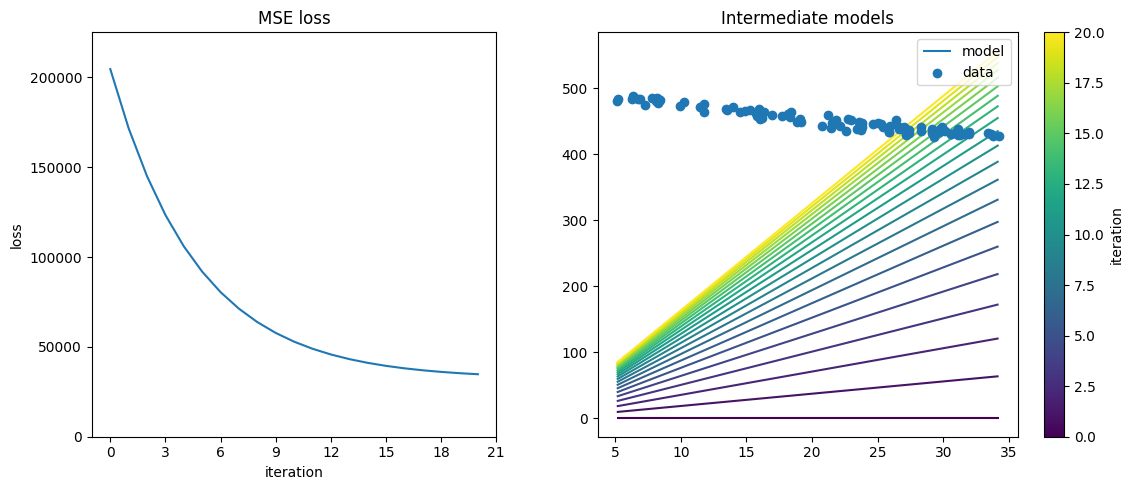

In [42]:
x, y = iml.load_powerplant()
model = SimpleRegressor()
model.fit(x, y, lr=0.0001)  # you need to choose a sufficiently small learning rate so that loss decreases
model.show_training()

The loss decreases over the 20 iterations. 
As for the intermediate models, the data point show a negative relationship (output decreases when temperature increases) but our final regression line has a positive slope : The model has not correctly learned yet.

The model is not converged, which is why we normalize the data in (c).

### (c) Now, normalize your data in some way and run `fit()` and `show_training()` again, ensuring that you converge to an acceptable model in 20 iterations.

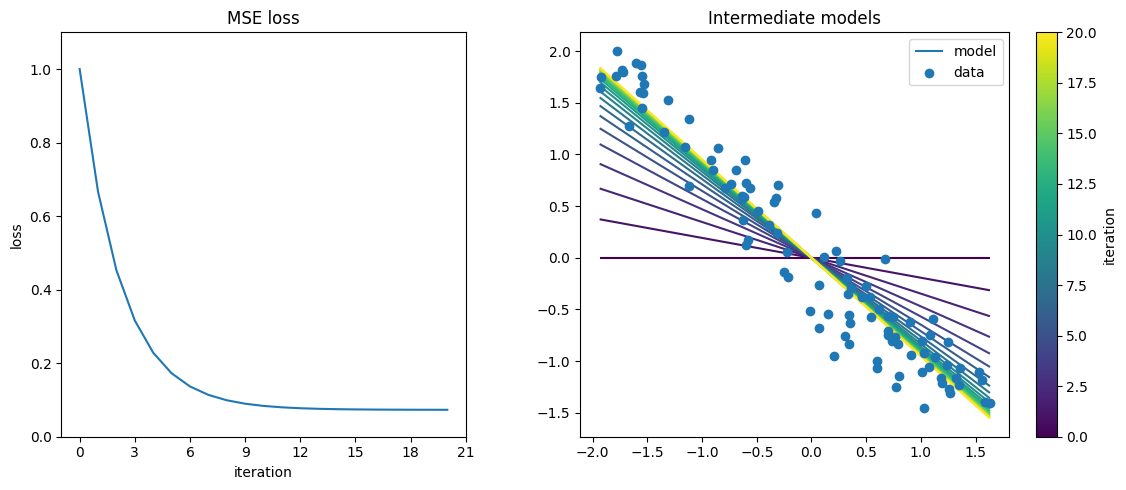

In [45]:
x_norm = (x - x.mean()) / x.std()
y_norm = (y - y.mean()) / y.std()

model = SimpleRegressor()
model.fit(x_norm, y_norm, lr=0.1)
model.show_training()

The MSE loss curve is quickly decreasing and approaching zero which means that the model has converged. It is correctly learning. Over the 20 iterations, the regression lines seem to fit the data better

## Part 3: k-Means and PCA

### (a) Suppose we didn't have access to the species attribute of the iris dataset. Implement the Lloyd-Forgy algorithm for $k$-means and use it to infer a partition of the iris dataset into three species. Compute the confusion matrix and the accuracy of the partition relative to the true species.

In [31]:
iris = iml.load_iris()
X = iris.data
species = iris.target
k = 3

def forgy(X, k): # picking k random flowers as the initial centroids
    indices = np.random.choice(len(X), k, replace=False)
    return X[indices]


def lloyd(X, centroids, max_steps=100):
    k = len(centroids)
    for step in range(max_steps):
        # assigning to nearest centroid
        labels = np.zeros(len(X), dtype=int)
        for i in range(len(X)):
            distances = [np.linalg.norm(X[i] - centroids[c]) for c in range(k)]
            labels[i] = np.argmin(distances)

        # update centroids
        new_centroids = np.zeros_like(centroids)
        for c in range(k):
            new_centroids[c] = X[labels == c].mean(axis=0)

        # stop when the centroids don't change anymore
        if np.allclose(new_centroids, centroids):
            break
        centroids = new_centroids

    return labels, centroids


np.random.seed(5)
initial_centroids = forgy(X, k)
labels, centroids = lloyd(X, initial_centroids)

# we named each cluster created by the algorithm with the name of the species that appears most in it (for better visualisation)
predicted = np.zeros(len(X), dtype=int)
for c in range(k):
    most_common = np.bincount(species[labels == c]).argmax()
    predicted[labels == c] = most_common

# confusion matrix and accuracy to compare the predicted classes with the actual dataset and evaluate the model
table = pd.crosstab(iris.target_names[species], iris.target_names[predicted],rownames=["true"], colnames=["predicted"])
print(table)

accuracy = (predicted == species).mean()
print("accuracy:", accuracy)

predicted   setosa  versicolor  virginica
true                                     
setosa          50           0          0
versicolor       0          48          2
virginica        0          14         36
accuracy: 0.8933333333333333


### (b) Investigate `data/ulu.csv` using PCA and explain how this dataset was produced. Using scikit-learn, run both $k$-means clustering and DBSCAN on this dataset. Which method produces more reasonable "clusters"?

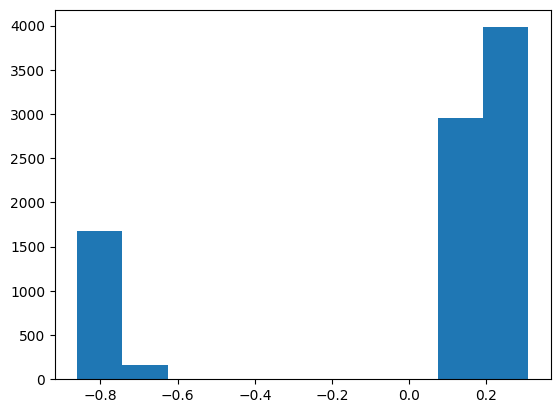

[0.8730992  0.11963923 0.00726156]


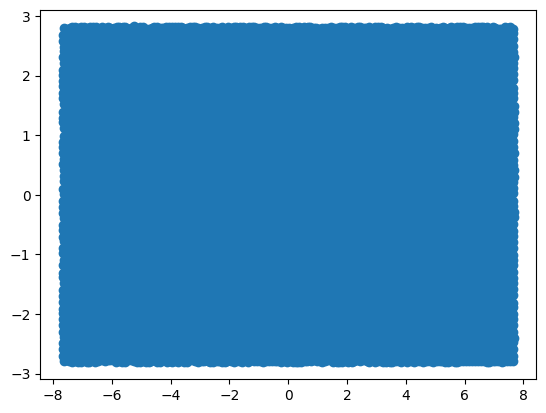

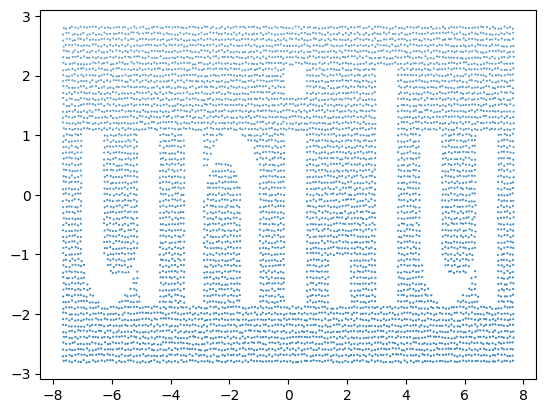

In [32]:
ulu = iml.load_ulu()
pca = PCA(n_components=3)
x = pca.fit_transform(ulu)
plt.hist(x[:, 2])  # x[:, 2] is the third principal component returned by PCA
plt.show()

print(pca.explained_variance_ratio_)

plt.figure()
plt.scatter(x[:, 0], x[:, 1])
plt.show()
plt.scatter(x[:, 0], x[:, 1], x[:, 2])
plt.show()



The variance ratio shows that the third principal component explains almost nothing, so the first two dimensions explain most of the variance (≈99%). However, its histogram shows two separate groups : it suggests that PC3 separates the two groups. Indeed, without adding the third dimension we only get a rectangle, whereas, including PC3, we can distinguish the letter 'uni.lu'.

On the histogram, we can see that one group of points has a lower PC3 value than the other group. So we think the dataset was made by taking a flat rectangle of points, lifting the points of the letters “uni.lu” a bit on the z axis (3rd dimension). Then we could use a method to hide the 'text' that will be revealed by the PCA.


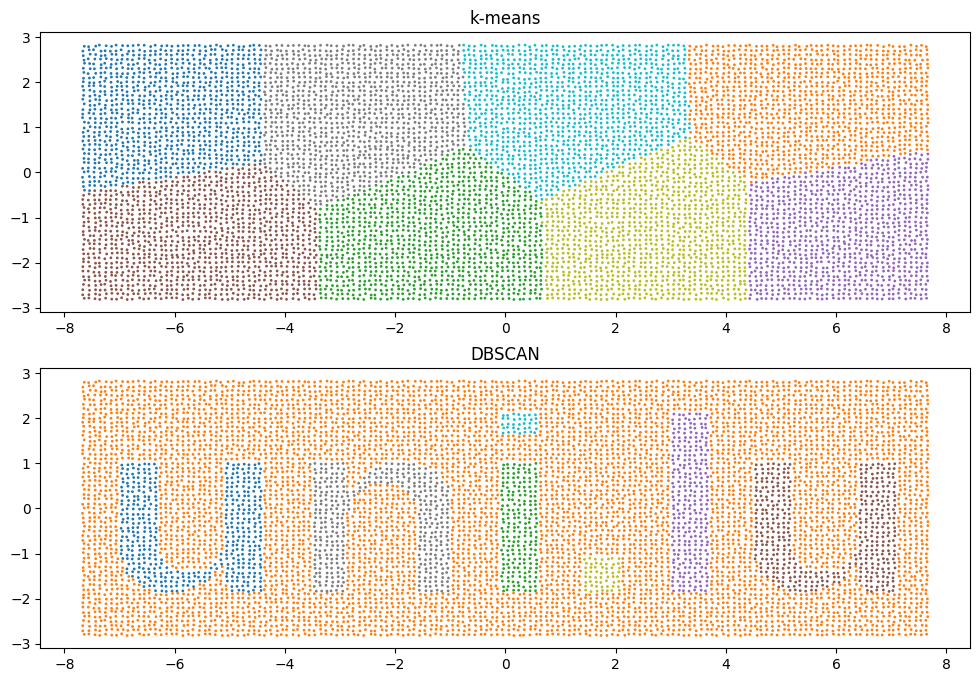

In [25]:
kmeans = KMeans().fit_predict(ulu)
dbscan = DBSCAN().fit_predict(ulu)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].scatter(x[:, 0], x[:, 1], c=kmeans, cmap="tab10", s=1)
axes[0].set_title("k-means")
axes[1].scatter(x[:, 0], x[:, 1], c=dbscan, cmap="tab10", s=1)
axes[1].set_title("DBSCAN")
plt.show()

Based on the plots of each method, we can conclude that DBSCAN produces more reasonable clusters for this dataset : It correctly identified the different characters hidden whereas k-means seems to have randomly classified the points.